# What happens when a fly cell loses the protein *pasilla*?

Most genes are not read in one piece: the cell cuts the mRNA and joins the pieces together, called **splicing**. Proteins that bind RNA decide how it's cut. One of them, in the fruit fly *Drosophila melanogaster*, is called **pasilla**. (Fly genes often have funny names; in the data, the pasilla gene is called **`ps`**.)

Researchers (Brooks et al. 2011) switched pasilla off in fly cells with **RNA interference** (**knockdown**): they added RNA that makes the cell destroy the pasilla mRNA. They sequenced **4 control** and **3 knockdown** samples. Some samples were sequenced with an older method (**single-end**: each RNA piece read from one side) and some with a newer one (**paired-end**: read from both sides).

### Your research question

> Did the knockdown work? And which genes change when pasilla is missing?

The data set is called `"pasilla"`.

In [1]:
setLanguage("en")   # language of the messages and plots below

Language: English



In [2]:
data <- loadDataset("pasilla")
data$samples

Loaded data set 'pasilla': 14599 genes, 7 samples.



,sample,condition,library
,<chr>,<fct>,<fct>
untreated1,untreated1,control,single_end
untreated2,untreated2,control,single_end
untreated3,untreated3,control,paired_end
untreated4,untreated4,control,paired_end
treated1,treated1,knockdown,single_end
treated2,treated2,knockdown,paired_end
treated3,treated3,knockdown,paired_end


### Your steps

Work through the same steps as in the tutorial. You can copy code from `01_tutorial_milk.ipynb` and change it: the **column names** and **group names** are different here. Below each step there is a cell for your code, and a hint you can open if you get stuck.

| Step | Functions from the tutorial |
|---|---|
| 1 Look at the data | `DGEList`, `plotLibrarySizes` |
| 2 Define the groups | `dge$samples$group <- …`, `table`, `plotGene` |
| 3 Prepare | `filterByExpr`, `normLibSizes`, `plotDistributions`, `plotSamples` |
| 4 Design and contrast | `model.matrix`, `makeContrasts` |
| 5 Test | `voom`, `lmFit`, `contrasts.fit`, `eBayes`, `decideTests` |
| 6 Interpret | `plotVolcano`, `showTop`, `plotGene` |

If a cell gives an error, read the message, check the spelling of the names, and make sure you ran the cells above.

## 1 Look at the data

Make a `DGEList` and look at the library sizes. Colour them by `library`. What do you notice?

[1] 14599     7

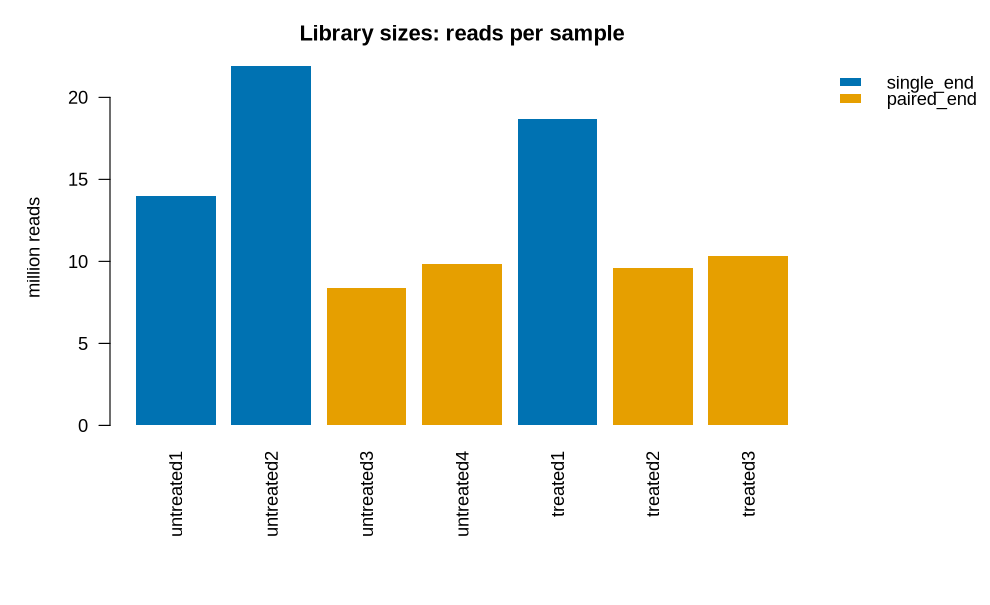

In [3]:
dge <- DGEList(counts = data$counts, samples = data$samples, genes = data$genes)
dim(dge)
plotLibrarySizes(dge, colour_by = "library")

<details><summary>💡 <b>Hint</b> (click to open)</summary>

As in the tutorial: `DGEList(counts = data$counts, samples = data$samples, genes = data$genes)`.

</details>

**Question: How different are the library sizes?**

✅ **Answer:** Between about **8 and 22 million** reads, almost 3 times as many in the largest as in the smallest. The single-end samples have more reads. That's no problem: normalisation takes care of it.

## 2 Groups, and a positive control

Set the groups (column `condition`). Then check first of all whether the knockdown worked: look at the gene `ps` itself. Such a check, where you know the expected answer, is called a **positive control**.


  control knockdown 
        4         3 

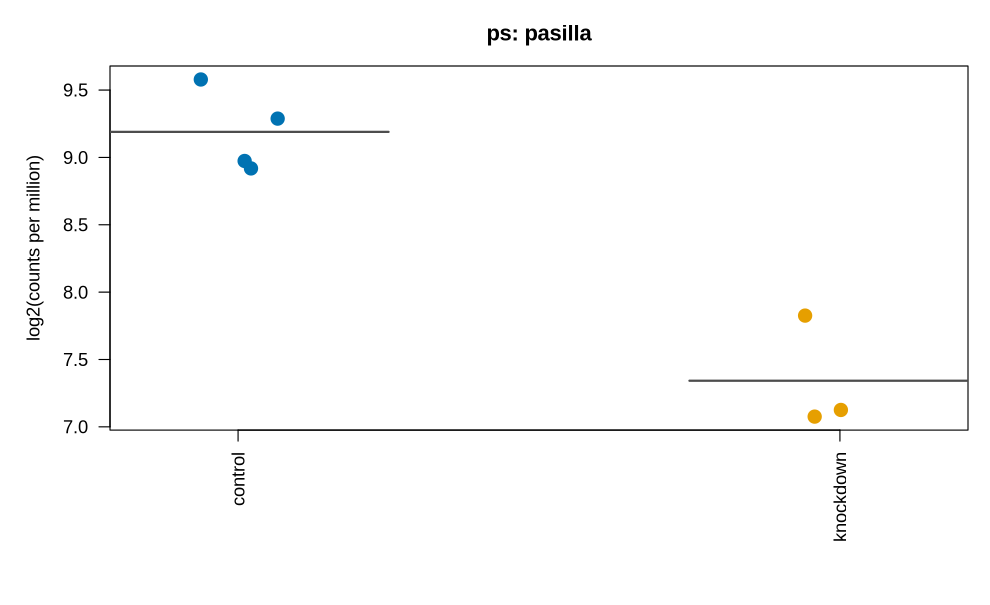

In [4]:
dge$samples$group <- dge$samples$condition
table(dge$samples$group)
plotGene(dge, "ps", group_by = "condition")

<details><summary>💡 <b>Hint</b> (click to open)</summary>

`dge$samples$group <- dge$samples$condition`, then `plotGene(dge, "ps", group_by = "condition")`.

</details>

## 3 Prepare

Filter, normalise and draw the sample map: colour it by `condition`, then by `library`.

[1] 7919    7

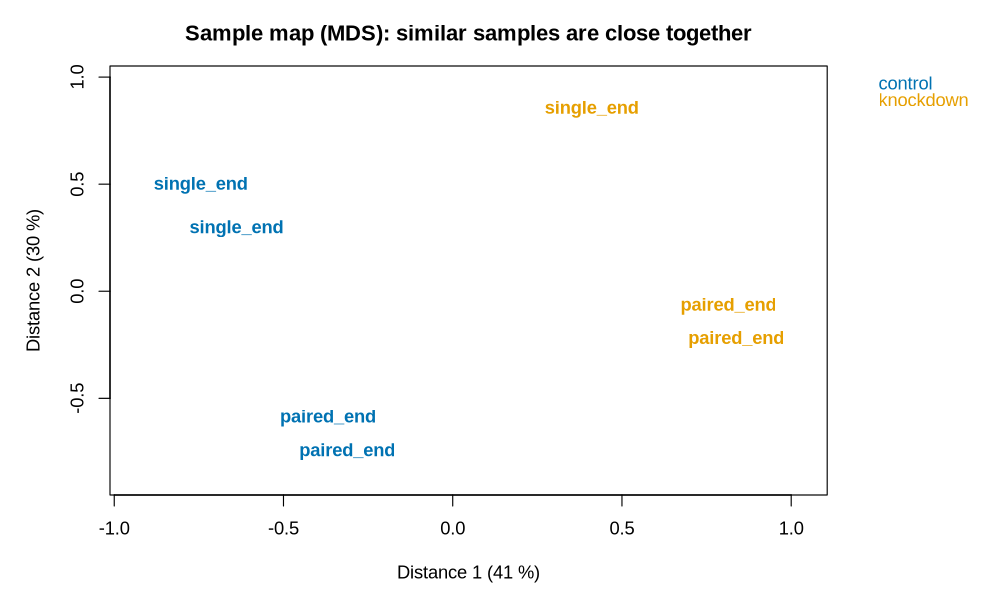

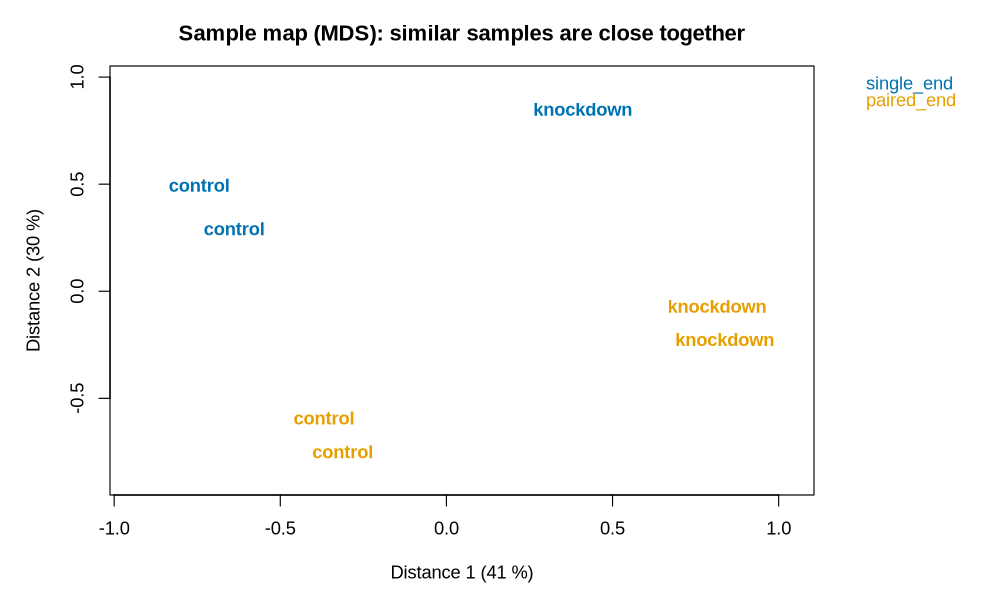

In [5]:
keep <- filterByExpr(dge)
dge <- dge[keep, , keep.lib.sizes = FALSE]
dge <- normLibSizes(dge)
dim(dge)
plotSamples(dge, colour_by = "condition", label_by = "library")
plotSamples(dge, colour_by = "library", label_by = "condition")

<details><summary>💡 <b>Hint</b> (click to open)</summary>

Same as part 3 of the tutorial. For the second map: `plotSamples(dge, colour_by = "library", label_by = "condition")`.

</details>

**Question: What separates the samples along distance 1 and along distance 2?**

✅ **Answer:** Distance 1 (41 %) separates **control from knockdown**. Distance 2 (30 %) separates **single-end from paired-end** samples. The sequencing method changes the counts a bit, even though the biology is the same. Such a technical difference is called a **batch effect**.

## 4 Design and contrast

The batch effect from step 3 is a problem: it adds variation that has nothing to do with pasilla. You can tell limma about it by putting the library type into the design:

```r
design <- model.matrix(~0 + condition + library, data = dge$samples)
```

Look at the column names, then write the contrast `knockdown_vs_control`.

In [6]:
design <- model.matrix(~0 + condition + library, data = dge$samples)
colnames(design)
contrasts <- makeContrasts(knockdown_vs_control = conditionknockdown - conditioncontrol, levels = design)
contrasts

[1] "conditioncontrol"   "conditionknockdown" "librarypaired_end"

,knockdown_vs_control
conditioncontrol,-1
conditionknockdown,1
librarypaired_end,0


<details><summary>💡 <b>Hint</b> (click to open)</summary>

The columns are `conditioncontrol`, `conditionknockdown` and `librarypaired_end`. The contrast: `conditionknockdown - conditioncontrol`.

</details>

## 5 Test

Test every gene and count the significant ones.

       knockdown_vs_control
Down                    601
NotSig                 6660
Up                      658

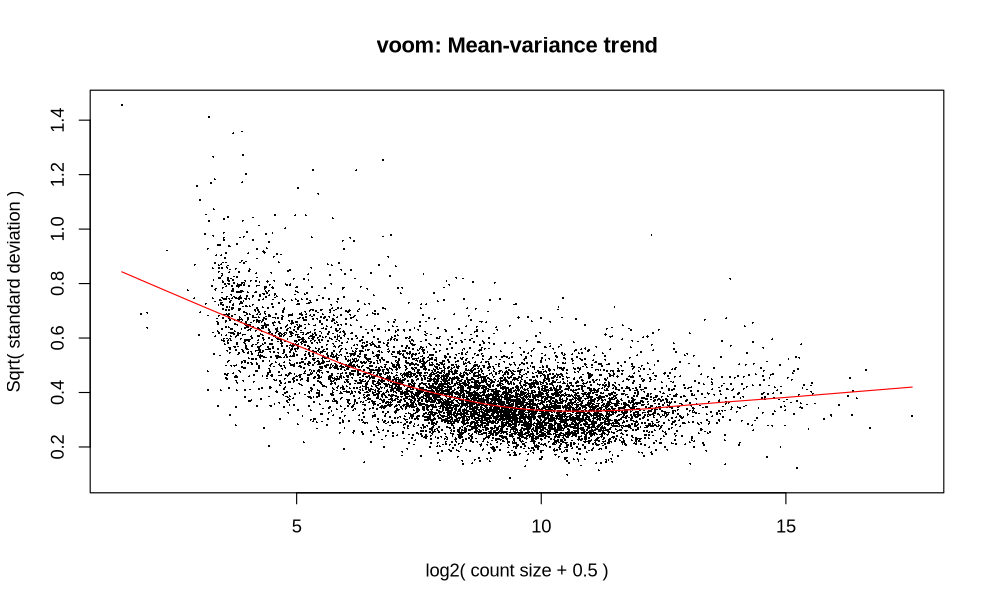

In [7]:
v <- voom(dge, design, plot = TRUE)
fit <- lmFit(v, design)
fit <- contrasts.fit(fit, contrasts)
fit <- eBayes(fit)
summary(decideTests(fit))

<details><summary>💡 <b>Hint</b> (click to open)</summary>

The cells from part 5 of the tutorial work unchanged.

</details>

**Question: How many genes go up, how many down?**

✅ **Answer:** About **660 up** and **600 down**, of about 7,900 tested genes.

## 6 Interpret

Draw the volcano plot and list the top genes. Where is `ps` itself? Look up some of the other genes on [FlyBase](https://flybase.org), the database for fly genes.

symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
Ant2,Adenine nucleotide translocase 2,2.86,7.2× higher,6.2,5.1e-08
Ama,Amalgam,2.64,6.2× higher,4.2,1.4e-06
LpR2,Lipophorin receptor 2,2.30,4.9× higher,3.2,1.5e-06
firl,firelighter,2.66,6.3× higher,2.1,5.0e-06
FBgn0033764,,3.40,10.6× higher,1.5,5.0e-06
bves,bves,1.25,2.4× higher,5.9,6.5e-06
Treh,Trehalase,1.11,2.2× higher,6.4,9.1e-06
FBgn0003501,,2.15,4.4× higher,4.1,1.1e-05
FBgn0052135,,1.43,2.7× higher,4.1,1.2e-05


symbol,description,logFC,change,AveExpr,adj.P.Val
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
sesB,stress-sensitive B,-3.12,8.7× lower,7.8,7.1e-08
Kal1,Kallmann syndrome 1,-4.62,24.6× lower,4.7,7.1e-08
Hml,Hemolectin,-2.19,4.6× lower,7.9,1.9e-07
CG3770,uncharacterized protein,-2.58,6.0× lower,5.2,1.9e-07
SPARC,"Secreted protein, acidic, cysteine-rich",-2.47,5.5× lower,11.3,1.9e-07
CG1544,uncharacterized protein,-4.19,18.2× lower,3.4,9.9e-07
gas,gasoline,-3.51,11.4× lower,3.4,1.5e-06
CG3168,uncharacterized protein,-2.42,5.3× lower,4.9,3.7e-06
FBgn0034434,,-3.62,12.3× lower,2.4,4.3e-06


,symbol,logFC,adj.P.Val
,<chr>,<dbl>,<dbl>
FBgn0261552,ps,-1.857211,4.724834e-05


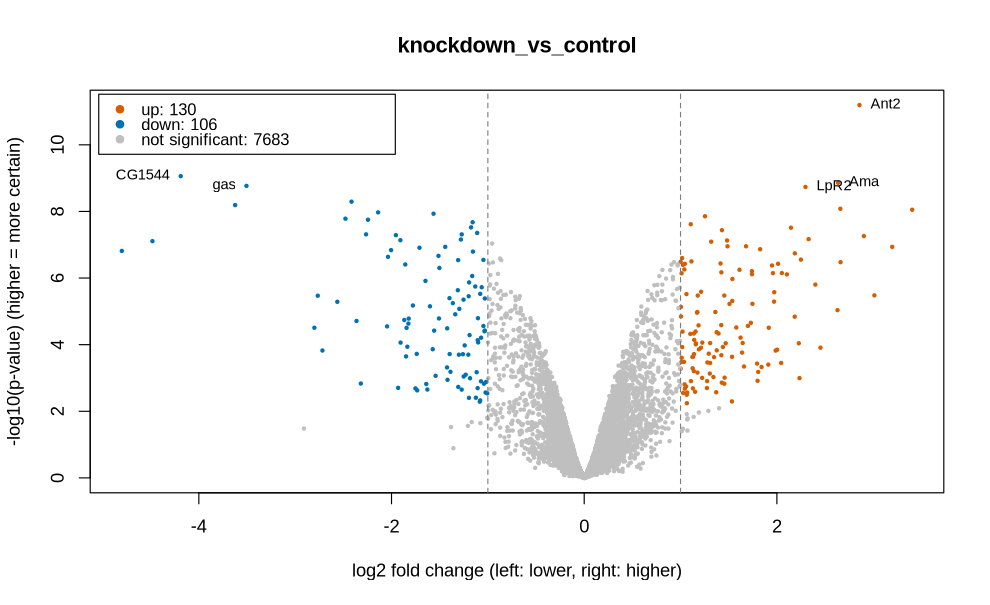

In [8]:
plotVolcano(fit, "knockdown_vs_control")
showTop(fit, "knockdown_vs_control", n = 15, direction = "up")
showTop(fit, "knockdown_vs_control", n = 15, direction = "down")
top <- topTable(fit, coef = "knockdown_vs_control", number = Inf)
top[top$symbol == "ps", c("symbol", "logFC", "adj.P.Val")]

<details><summary>💡 <b>Hint</b> (click to open)</summary>

To find one gene in the full results table: `top <- topTable(fit, coef = "knockdown_vs_control", number = Inf)`, then `top[top$symbol == "ps", ]`. Many fly genes are only called `CG…` + a number: nobody knows yet what they do!

</details>

## Your conclusion

Answer the research question in a few sentences: what did you compare, what did you find, and what does it mean? Be ready to show your volcano plot and your answer to the class.

✅ **Answer:** We compared 3 pasilla knockdown samples with 4 controls, with the library type in the design to remove the batch effect. The knockdown worked: `ps` itself is about **3.7 times lower** (logFC ≈ −1.9). About 660 genes went up and 600 down. Among the strongest changes are *Ant2* and *sesB*, two versions of the same mitochondrial transporter (one up, one down), and *Kal1*, *Hml* and *SPARC*. Many changed genes are uncharacterised (`CG…`). Because pasilla controls splicing, many of these genes may be its targets: this is the kind of list researchers start from to find out what an unknown protein does.

## Bonus: what if you ignore the batch effect?

Repeat steps 4 and 5 with `model.matrix(~0 + condition, data = dge$samples)` and compare the number of significant genes.

In [9]:
design0 <- model.matrix(~0 + condition, data = dge$samples)
contrasts0 <- makeContrasts(knockdown_vs_control = conditionknockdown - conditioncontrol, levels = design0)
fit0 <- eBayes(contrasts.fit(lmFit(voom(dge, design0), design0), contrasts0))
summary(decideTests(fit0))

       knockdown_vs_control
Down                    321
NotSig                 7249
Up                      349

✅ **Answer:** Without the library type only about **670** genes are significant instead of about **1,260**: the batch effect counts as noise and hides real changes. Good experiments avoid batch effects, and good analyses include the ones that can't be avoided.

<small>Software: limma (Ritchie et al. 2015) with voom (Law et al. 2014) and edgeR (Chen et al. 2025) in R. Full sources for all data sets at the end of `01_tutorial_milk.ipynb`.</small>